# 01. Feature Analysis & Engineering Recommendations

> **Role**: Role 3 — Data Preprocessing & Feature Engineering  
> **Project**: Project 18 — Water Quality Prediction via Gradient Boosting & DNN  
> **Course**: Semester 5 AML / DL  
> **Input Dataset**: `data/GeneratedOutput/01.EDA/final_eda_cleaned_dataset.parquet` (4,290,073 rows × 14 cols)  

---

### Notebook Objectives

1. **Column Taxonomy** — Classify every column as predictor, target, identifier, date, or metadata.  
2. **Feature Distributions** — Univariate distribution analysis for all 8 chemical predictors.  
3. **Correlations & Multicollinearity** — Pearson/Spearman heatmaps + Variance Inflation Factor (VIF).  
4. **Target Relationships** — Feature–target associations and class-wise profiles.  
5. **Target Leakage Audit** — Quantitative investigation of whether the 8 predictors mathematically determine the CCME WQI.  
6. **Feature Recommendations** — Retain, transform, or exclude with justification.  

---

## 1. Setup & Data Loading

Following the project convention established in `nootbooks/01.EDA/`, we load the **physically validated clean dataset** exported by the EDA pipeline (Role 2). This dataset has already had sentinel values (`-999999.0`), sensor calibration bugs (`pH = 67115`), and physically impossible readings removed.

In [1]:
# ── Setup & Environment ──────────────────────────────────────────────────────
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['figure.dpi'] = 100

# ── Data Paths (relative from nootbooks/you_task/) ────────────────────────────
# Following the existing EDA notebook convention with fallback paths
DATA_PATH = 'data/GeneratedOutput/01.EDA/final_eda_cleaned_dataset.parquet'
RAW_DATA_PATH = 'data/Dataset/Parquet/Combined Data/Combined_dataset.parquet'

if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join('..', '..', DATA_PATH)
    RAW_DATA_PATH = os.path.join('..', '..', RAW_DATA_PATH)

# ── Load Cleaned Dataset from EDA Pipeline ───────────────────────────────────
df = pd.read_parquet(DATA_PATH)
print(f"✅ Loaded EDA-cleaned dataset: {len(df):,} rows × {len(df.columns)} columns")
print(f"   Memory footprint: {df.memory_usage(deep=True).sum() / (1024**2):.1f} MB")

Matplotlib is building the font cache; this may take a moment.


✅ Loaded EDA-cleaned dataset: 4,290,073 rows × 14 columns
   Memory footprint: 659.6 MB


## 2. Column Taxonomy

Based on the project `AGENT.md` and `README.md` specifications (Section 4: Target Schema & Feature Definitions), the 14 columns are classified into the following groups:

| Group | Columns | Purpose |
|---|---|---|
| **Metadata / Identifiers** | `Country`, `Area` | Geographic identifiers; not direct numeric predictors |
| **Categorical Context** | `Waterbody Type` | Environmental context (River, Stream, Lake, etc.) |
| **Date** | `Date` | Temporal reference (DD-MM-YYYY string) |
| **Chemical / Physical Predictors (X)** | 8 columns | Input features for ML/DL models |
| **Target Variables (y)** | `CCME_Values`, `CCME_WQI` | Regression and classification targets |

In [2]:
# ── Column Classification ────────────────────────────────────────────────────

# Identifiers / Location
id_cols = ['Country', 'Area']

# Categorical metadata
meta_cols = ['Waterbody Type']

# Date column
date_cols = ['Date']

# Chemical & Physical Predictors (X) — as defined in AGENT.md Section 4
chemical_cols = [
    'Ammonia (mg/l)',
    'Biochemical Oxygen Demand (mg/l)',
    'Dissolved Oxygen (mg/l)',
    'Orthophosphate (mg/l)',
    'pH (ph units)',
    'Temperature (cel)',
    'Nitrogen (mg/l)',
    'Nitrate (mg/l)'
]

# Target Variables (y)
target_regression = 'CCME_Values'      # Continuous: 0.0 – 100.0
target_classification = 'CCME_WQI'     # Categorical: Excellent / Good / Fair / Marginal / Poor
target_cols = [target_regression, target_classification]

# Validation: confirm all columns are accounted for
all_classified = set(id_cols + meta_cols + date_cols + chemical_cols + target_cols)
all_actual = set(df.columns)
assert all_classified == all_actual, f"Mismatch: {all_actual - all_classified}"

# Display taxonomy table
taxonomy = pd.DataFrame({
    'Column': df.columns,
    'Dtype': df.dtypes.astype(str).values,
    'Group': [
        'Identifier' if c in id_cols else
        'Metadata' if c in meta_cols else
        'Date' if c in date_cols else
        'Predictor (X)' if c in chemical_cols else
        'Target (y)'
        for c in df.columns
    ],
    'Non-Null %': [(df[c].notna().mean() * 100) for c in df.columns],
    'Unique Values': [df[c].nunique() for c in df.columns]
})
taxonomy['Non-Null %'] = taxonomy['Non-Null %'].round(2)
print("\n📋 Column Taxonomy (14 columns):")
print("=" * 100)
display(taxonomy.to_string(index=False))


📋 Column Taxonomy (14 columns):


'                          Column   Dtype         Group  Non-Null %  Unique Values\n                         Country     str    Identifier      100.00              7\n                            Area     str    Identifier      100.00          64363\n                  Waterbody Type     str      Metadata      100.00             13\n                            Date     str          Date      100.00          24012\n                  Ammonia (mg/l) float64 Predictor (X)       65.75          13947\nBiochemical Oxygen Demand (mg/l) float64 Predictor (X)       65.82           4844\n         Dissolved Oxygen (mg/l) float64 Predictor (X)       73.41          18048\n           Orthophosphate (mg/l) float64 Predictor (X)       65.75          10566\n                   pH (ph units) float64 Predictor (X)       72.01           4870\n               Temperature (cel) float64 Predictor (X)       99.85          17824\n                 Nitrogen (mg/l) float64 Predictor (X)       65.75          16183\n   

## 3. Predictor Feature Distributions

Understanding the marginal distributions of each predictor is essential for:
- Choosing appropriate scaling (StandardScaler vs RobustScaler for skewed features)
- Identifying heavy tails that may benefit from log or Box-Cox transforms
- Detecting zero-inflation in chemical concentration measurements

In [3]:
# ── Descriptive Statistics for All Chemical Predictors ────────────────────────
desc = df[chemical_cols].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T
desc['skewness'] = df[chemical_cols].skew()
desc['kurtosis'] = df[chemical_cols].kurtosis()
desc['null_%'] = (df[chemical_cols].isnull().mean() * 100).round(2)
desc['zero_%'] = ((df[chemical_cols] == 0).sum() / len(df) * 100).round(2)

print("📊 Predictor Summary Statistics:")
display(desc.round(4))

📊 Predictor Summary Statistics:


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skewness,kurtosis,null_%,zero_%
Ammonia (mg/l),2820525.0,1.1651,5.6227,0.0,0.0090,0.021,0.03,0.055,0.319,4.44,26.50,200.00,12.0465,225.2401,34.25,0.03
Biochemical Oxygen Demand (mg/l),2823923.0,4.8875,16.4160,0.0,0.7000,1.000,1.60,2.700,2.850,11.70,68.00,534.50,10.2536,118.5609,34.18,0.00
Dissolved Oxygen (mg/l),3149182.0,9.7872,2.1218,0.0,2.0500,5.000,9.39,10.200,10.900,12.20,13.70,23.75,-1.4785,3.7406,26.59,0.01
Orthophosphate (mg/l),2820525.0,0.7112,2.0861,0.0,0.0040,0.010,0.04,0.108,0.228,4.91,9.14,100.00,8.9130,205.5659,34.25,0.02
pH (ph units),3089083.0,7.7297,0.4562,3.0,6.3500,6.980,7.51,7.780,8.000,8.32,8.71,12.00,-1.0916,8.0056,27.99,0.00
Temperature (cel),4283519.0,13.6878,6.6557,-1.9,1.7000,4.540,9.30,11.900,17.200,27.25,31.15,50.00,0.7630,0.3167,0.15,0.06
Nitrogen (mg/l),2820525.0,5.2192,6.2032,0.0,0.0190,0.200,0.80,4.000,6.340,18.40,30.40,46.00,2.3921,7.2160,34.25,0.00
Nitrate (mg/l),2823860.0,4.7649,6.0959,0.0,0.0465,0.200,1.17,4.500,4.930,14.50,28.30,790.02,6.9601,179.4327,34.18,0.02


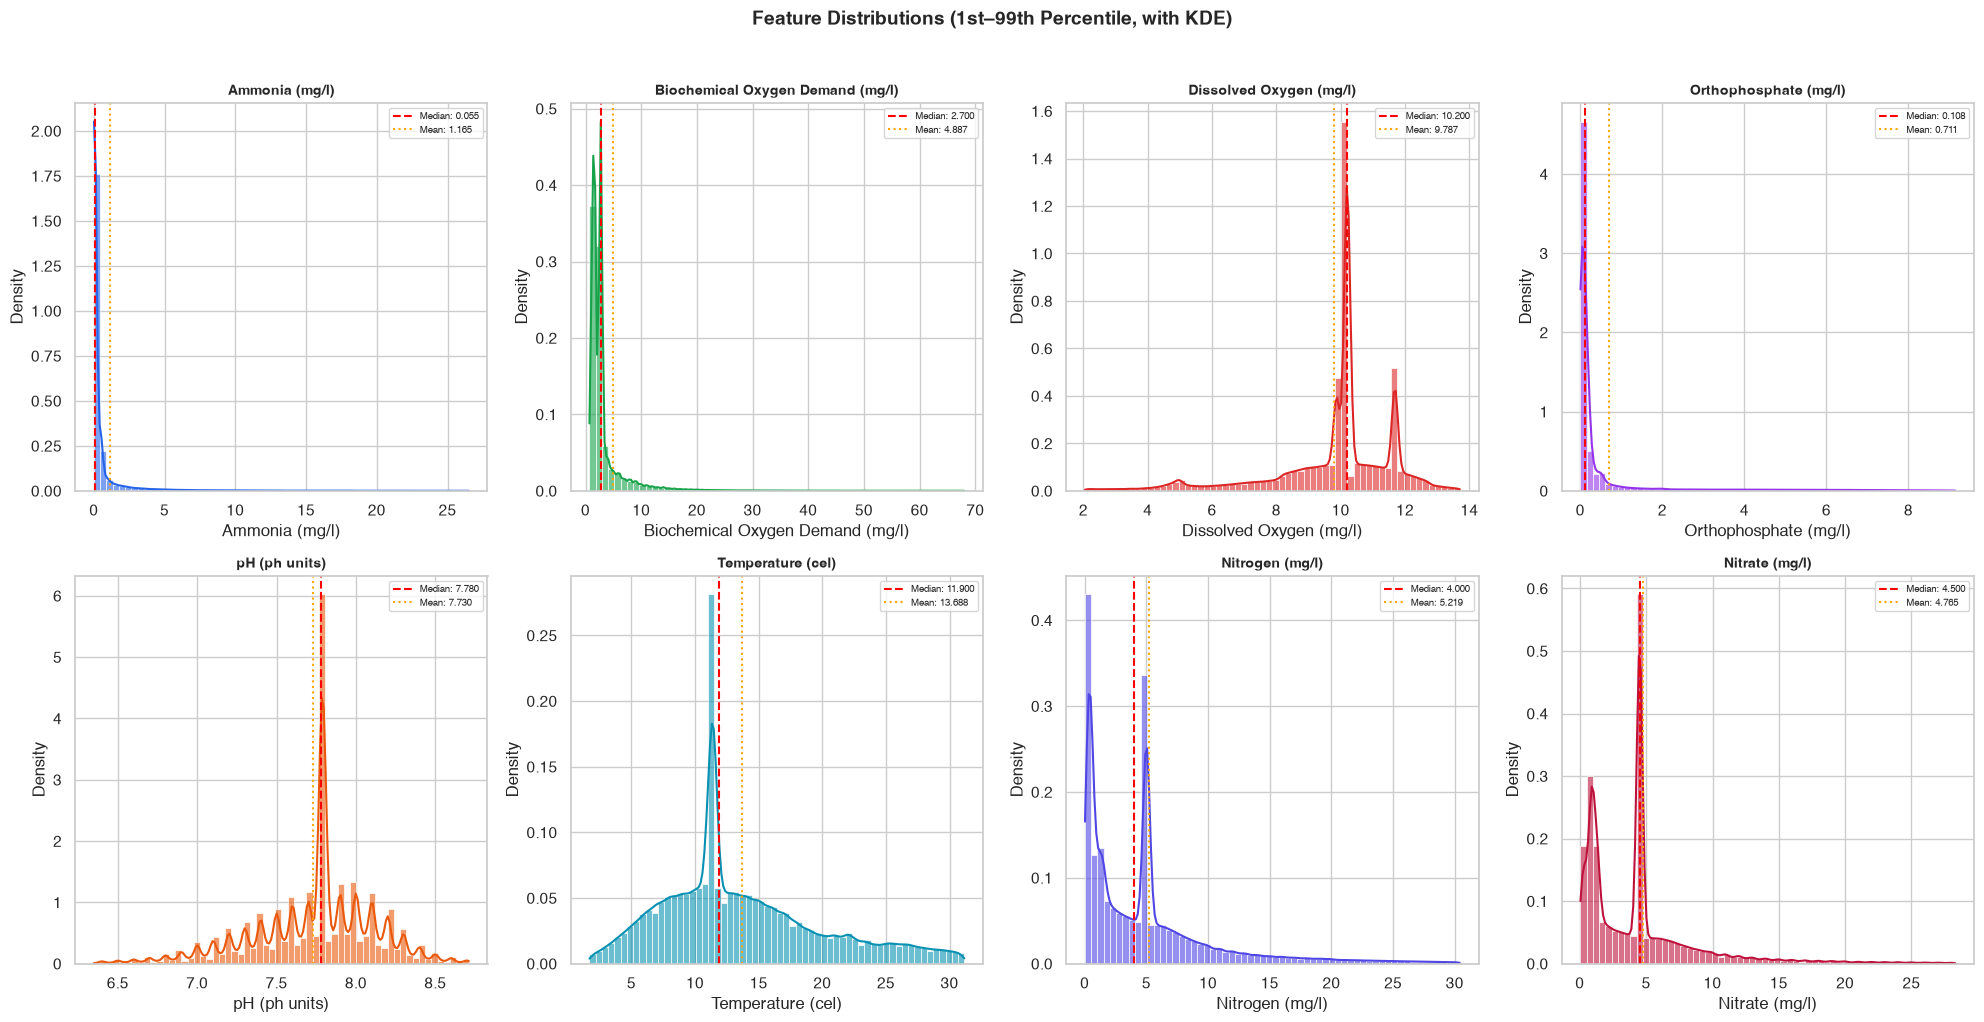

In [4]:
# ── Distribution Plots: Histograms + KDE for all 8 predictors ────────────────
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.ravel()

colors = ['#2563eb', '#16a34a', '#dc2626', '#9333ea', '#ea580c', '#0891b2', '#4f46e5', '#be123c']

for i, col in enumerate(chemical_cols):
    ax = axes[i]
    data = df[col].dropna()
    
    # Clip extreme outliers for visualization (use 1st/99th percentile)
    p01, p99 = data.quantile(0.01), data.quantile(0.99)
    data_clipped = data[(data >= p01) & (data <= p99)]
    
    sns.histplot(data_clipped, bins=60, kde=True, color=colors[i], ax=ax,
                 stat='density', alpha=0.6, edgecolor='white', linewidth=0.5)
    ax.axvline(data.median(), color='red', linestyle='--', lw=1.5, label=f'Median: {data.median():.3f}')
    ax.axvline(data.mean(), color='orange', linestyle=':', lw=1.5, label=f'Mean: {data.mean():.3f}')
    ax.set_title(col, fontsize=10, fontweight='bold')
    ax.legend(fontsize=7)
    ax.set_ylabel('Density')

fig.suptitle('Feature Distributions (1st–99th Percentile, with KDE)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

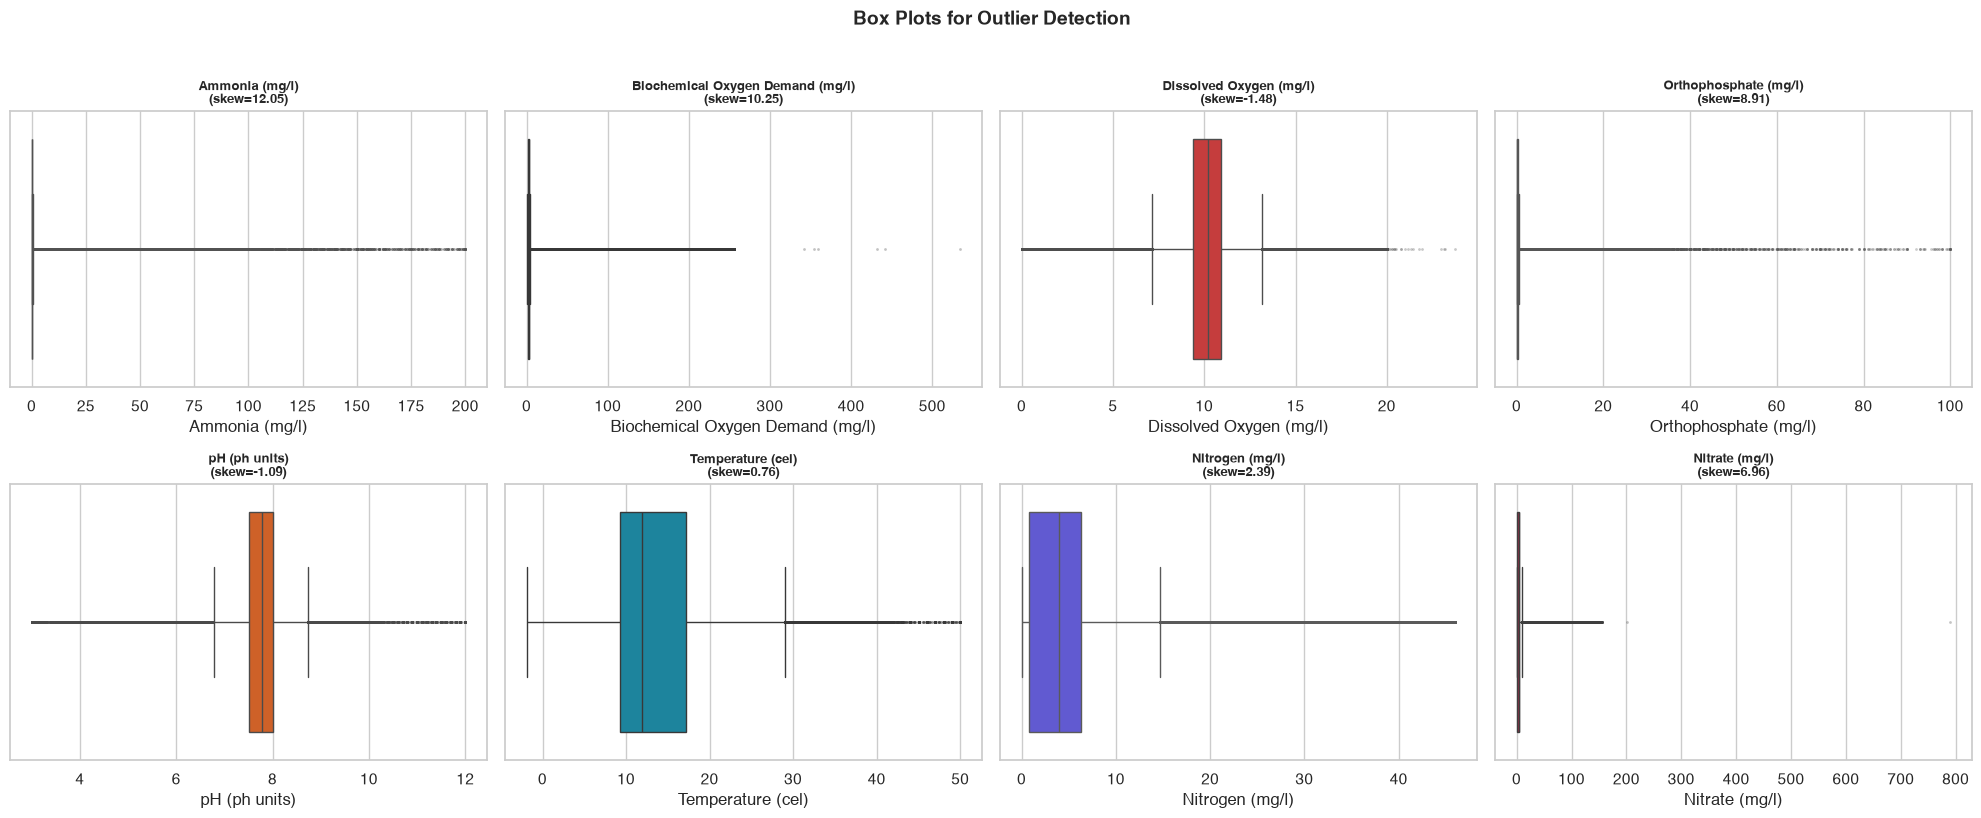

In [5]:
# ── Box Plots for Outlier Detection ──────────────────────────────────────────
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
axes = axes.ravel()

for i, col in enumerate(chemical_cols):
    ax = axes[i]
    data = df[col].dropna()
    
    # Use log scale for right-skewed features (skewness > 2)
    use_log = data.skew() > 2 and data.min() >= 0
    
    sns.boxplot(x=data, ax=ax, color=colors[i], fliersize=1, flierprops={'alpha': 0.3})
    ax.set_title(f"{col}\n(skew={data.skew():.2f})", fontsize=9, fontweight='bold')
    if use_log and data.min() > 0:
        ax.set_xscale('log')
        ax.set_xlabel('Log Scale')

fig.suptitle('Box Plots for Outlier Detection', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 3.1 Skewness Assessment & Transformation Candidates

Highly right-skewed features (skewness > 2) are common for chemical concentrations because:
- Most water samples are clean (low concentrations near zero)
- A few heavily polluted samples drive extreme right tails

These features may benefit from **log1p** or **Box-Cox** transforms for tree models and are **essential** to scale/transform for the MLP neural network.

In [6]:
# ── Skewness Summary & Transformation Recommendations ────────────────────────
skewness_df = pd.DataFrame({
    'Feature': chemical_cols,
    'Skewness': [df[c].skew() for c in chemical_cols],
    'Kurtosis': [df[c].kurtosis() for c in chemical_cols],
    'Min': [df[c].min() for c in chemical_cols],
    'Has Negatives': [bool((df[c] < 0).any()) for c in chemical_cols],
    'Zero %': [((df[c] == 0).sum() / df[c].notna().sum() * 100) for c in chemical_cols]
})

def recommend_transform(row):
    if abs(row['Skewness']) < 1:
        return 'None needed (near-symmetric)'
    elif row['Has Negatives']:
        return 'Yeo-Johnson (handles negatives)'
    elif row['Min'] >= 0 and row['Skewness'] > 2:
        return 'log1p (strong right skew, non-negative)'
    elif row['Skewness'] > 1:
        return 'sqrt or log1p (moderate right skew)'
    else:
        return 'Consider Box-Cox'

skewness_df['Recommended Transform'] = skewness_df.apply(recommend_transform, axis=1)
skewness_df['Skewness'] = skewness_df['Skewness'].round(3)
skewness_df['Kurtosis'] = skewness_df['Kurtosis'].round(3)
skewness_df['Zero %'] = skewness_df['Zero %'].round(2)

print("\n📐 Skewness Analysis & Recommended Transforms:")
display(skewness_df.to_string(index=False))


📐 Skewness Analysis & Recommended Transforms:


'                         Feature  Skewness  Kurtosis  Min  Has Negatives  Zero %                   Recommended Transform\n                  Ammonia (mg/l)    12.046   225.240  0.0          False    0.04 log1p (strong right skew, non-negative)\nBiochemical Oxygen Demand (mg/l)    10.254   118.561  0.0          False    0.00 log1p (strong right skew, non-negative)\n         Dissolved Oxygen (mg/l)    -1.479     3.741  0.0          False    0.01                        Consider Box-Cox\n           Orthophosphate (mg/l)     8.913   205.566  0.0          False    0.02 log1p (strong right skew, non-negative)\n                   pH (ph units)    -1.092     8.006  3.0          False    0.00                        Consider Box-Cox\n               Temperature (cel)     0.763     0.317 -1.9           True    0.06            None needed (near-symmetric)\n                 Nitrogen (mg/l)     2.392     7.216  0.0          False    0.00 log1p (strong right skew, non-negative)\n                  Nitra

## 4. Correlation Analysis

We examine both:
- **Pearson correlation**: Linear relationships (sensitive to outliers)
- **Spearman rank correlation**: Monotonic non-linear relationships (robust to outliers)

This analysis uses a stratified sample of complete cases to ensure computational tractability while maintaining statistical validity.

In [7]:
# ── Complete-Case Subset for Correlation Analysis ────────────────────────────
# Use complete cases only (no NaNs in any chemical predictor) for clean correlations
df_complete = df.dropna(subset=chemical_cols).copy()
print(f"Complete cases (no missing in any predictor): {len(df_complete):,} / {len(df):,} ({len(df_complete)/len(df)*100:.1f}%)")

# If too large, sample for correlation computation
if len(df_complete) > 500_000:
    df_corr = df_complete.sample(500_000, random_state=42)
    print(f"Sampled to {len(df_corr):,} rows for correlation analysis")
else:
    df_corr = df_complete.copy()

# Compute correlation matrices
analysis_cols = chemical_cols + [target_regression]
pearson_corr = df_corr[analysis_cols].corr(method='pearson')
spearman_corr = df_corr[analysis_cols].corr(method='spearman')

Complete cases (no missing in any predictor): 2,820,438 / 4,290,073 (65.7%)


Sampled to 500,000 rows for correlation analysis


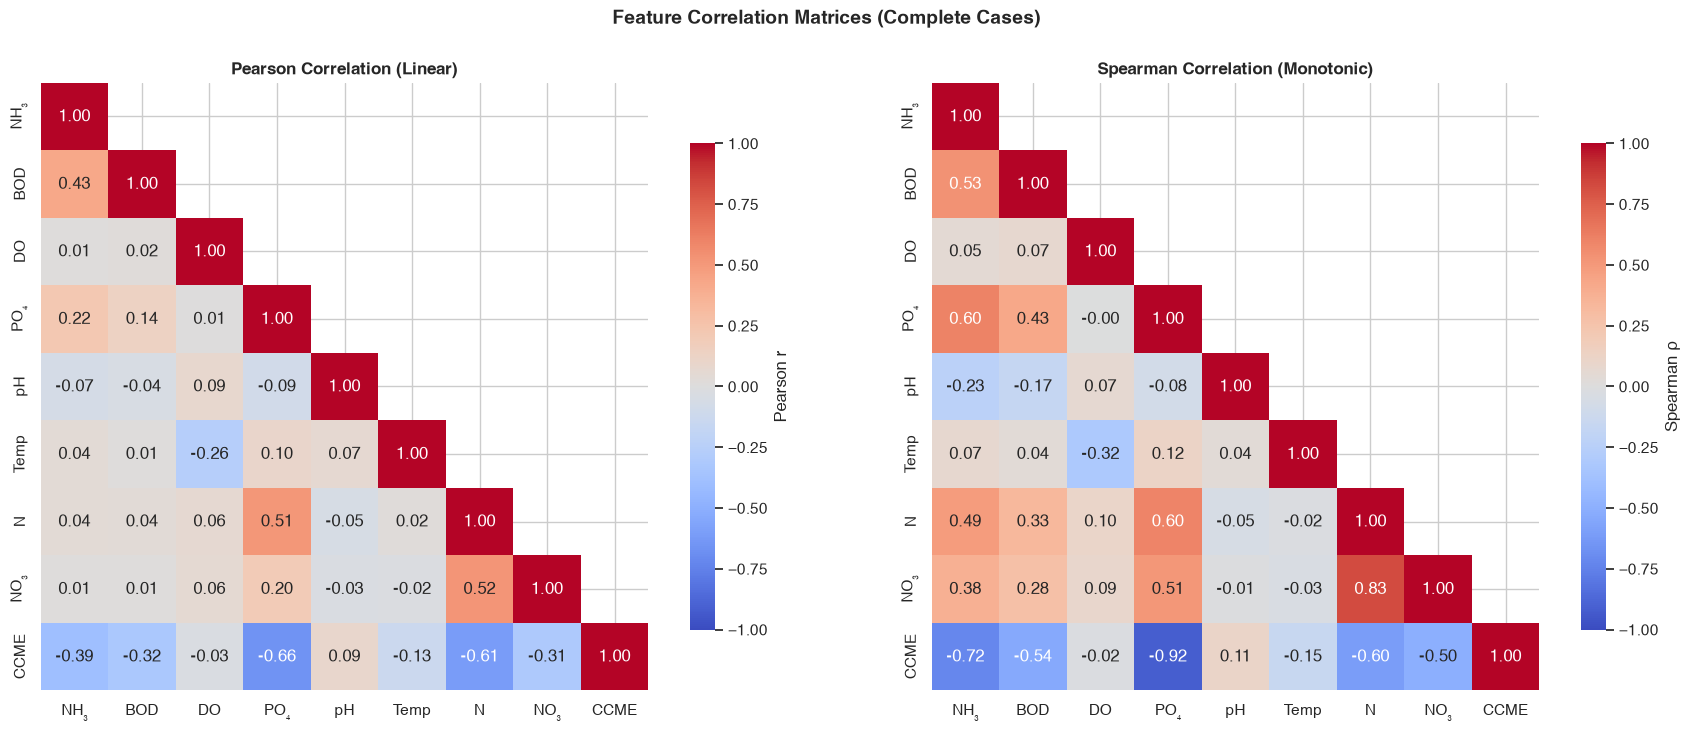

In [8]:
# ── Dual Correlation Heatmaps ────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Short labels for readability
short_labels = ['NH₃', 'BOD', 'DO', 'PO₄', 'pH', 'Temp', 'N', 'NO₃', 'CCME']

# Pearson
mask = np.triu(np.ones_like(pearson_corr, dtype=bool), k=1)
sns.heatmap(pearson_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            ax=axes[0], square=True, mask=mask,
            xticklabels=short_labels, yticklabels=short_labels,
            cbar_kws={'label': 'Pearson r', 'shrink': 0.8})
axes[0].set_title('Pearson Correlation (Linear)', fontweight='bold')

# Spearman
sns.heatmap(spearman_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            ax=axes[1], square=True, mask=mask,
            xticklabels=short_labels, yticklabels=short_labels,
            cbar_kws={'label': 'Spearman ρ', 'shrink': 0.8})
axes[1].set_title('Spearman Correlation (Monotonic)', fontweight='bold')

fig.suptitle('Feature Correlation Matrices (Complete Cases)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


🎯 Feature–Target Correlations (sorted by |Spearman ρ|):


'                         Feature  Pearson r  Spearman ρ\n           Orthophosphate (mg/l)    -0.6564     -0.9168\n                  Ammonia (mg/l)    -0.3932     -0.7243\n                 Nitrogen (mg/l)    -0.6099     -0.6032\nBiochemical Oxygen Demand (mg/l)    -0.3208     -0.5360\n                  Nitrate (mg/l)    -0.3092     -0.5034\n               Temperature (cel)    -0.1306     -0.1497\n                   pH (ph units)     0.0873      0.1112\n         Dissolved Oxygen (mg/l)    -0.0300     -0.0229'

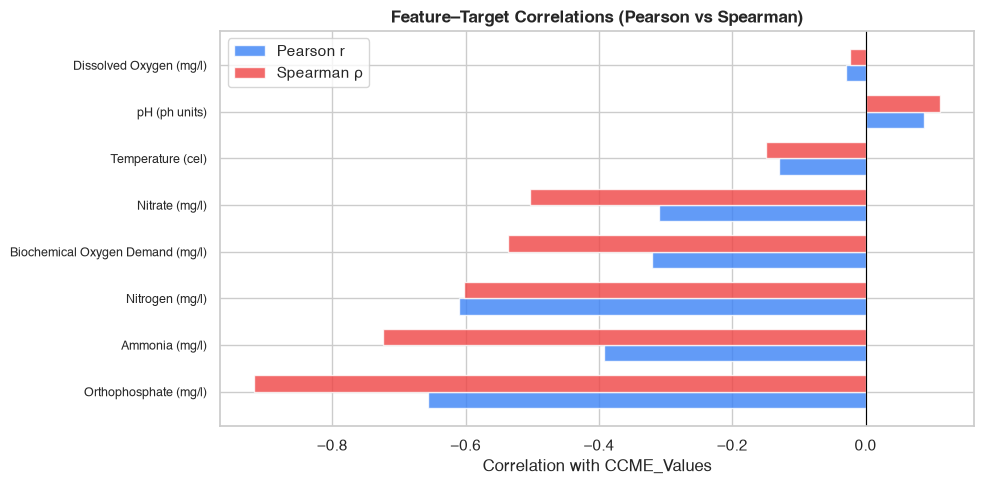

In [9]:
# ── Feature Correlations with Target (ranked) ────────────────────────────────
target_corr = pd.DataFrame({
    'Feature': chemical_cols,
    'Pearson r': [pearson_corr.loc[c, target_regression] for c in chemical_cols],
    'Spearman ρ': [spearman_corr.loc[c, target_regression] for c in chemical_cols]
}).sort_values('Spearman ρ', key=abs, ascending=False)

print("\n🎯 Feature–Target Correlations (sorted by |Spearman ρ|):")
display(target_corr.round(4).to_string(index=False))

# Visualize
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(target_corr))
width = 0.35
bars1 = ax.barh(x - width/2, target_corr['Pearson r'], width, label='Pearson r', color='#3b82f6', alpha=0.8)
bars2 = ax.barh(x + width/2, target_corr['Spearman ρ'], width, label='Spearman ρ', color='#ef4444', alpha=0.8)
ax.set_yticks(x)
ax.set_yticklabels(target_corr['Feature'], fontsize=9)
ax.set_xlabel('Correlation with CCME_Values')
ax.set_title('Feature–Target Correlations (Pearson vs Spearman)', fontweight='bold')
ax.axvline(0, color='black', linewidth=0.8)
ax.legend()
plt.tight_layout()
plt.show()

## 5. Multicollinearity Analysis (VIF)

Variance Inflation Factor (VIF) quantifies how much the variance of a regression coefficient is inflated due to collinearity with other predictors:
- **VIF = 1**: No collinearity
- **VIF 1–5**: Low collinearity (acceptable)
- **VIF 5–10**: Moderate collinearity (monitor)
- **VIF > 10**: High collinearity (consider removal or combining)

We compute VIF on the complete-case subset with standardized features.

In [10]:
# ── Variance Inflation Factor (VIF) ──────────────────────────────────────────
from sklearn.preprocessing import StandardScaler

# Use a manageable sample for VIF computation
vif_sample = df_complete[chemical_cols].sample(min(200_000, len(df_complete)), random_state=42).copy()

# Standardize features before VIF computation
scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(vif_sample),
    columns=chemical_cols
)

# Compute VIF for each feature
from numpy.linalg import inv

corr_matrix = X_scaled.corr().values
try:
    vif_values = np.diag(inv(corr_matrix))
except np.linalg.LinAlgError:
    # If singular, use pseudo-inverse
    vif_values = np.diag(np.linalg.pinv(corr_matrix))

vif_df = pd.DataFrame({
    'Feature': chemical_cols,
    'VIF': vif_values
}).sort_values('VIF', ascending=False)

vif_df['Interpretation'] = vif_df['VIF'].apply(
    lambda v: '🟢 Low' if v < 5 else ('🟡 Moderate' if v < 10 else '🔴 High')
)

print("\n🔍 Variance Inflation Factor (VIF) Analysis:")
display(vif_df.round(3).to_string(index=False))


🔍 Variance Inflation Factor (VIF) Analysis:


'                         Feature   VIF Interpretation\n                 Nitrogen (mg/l) 1.793          🟢 Low\n           Orthophosphate (mg/l) 1.450          🟢 Low\n                  Nitrate (mg/l) 1.378          🟢 Low\n                  Ammonia (mg/l) 1.262          🟢 Low\nBiochemical Oxygen Demand (mg/l) 1.214          🟢 Low\n               Temperature (cel) 1.102          🟢 Low\n         Dissolved Oxygen (mg/l) 1.097          🟢 Low\n                   pH (ph units) 1.031          🟢 Low'

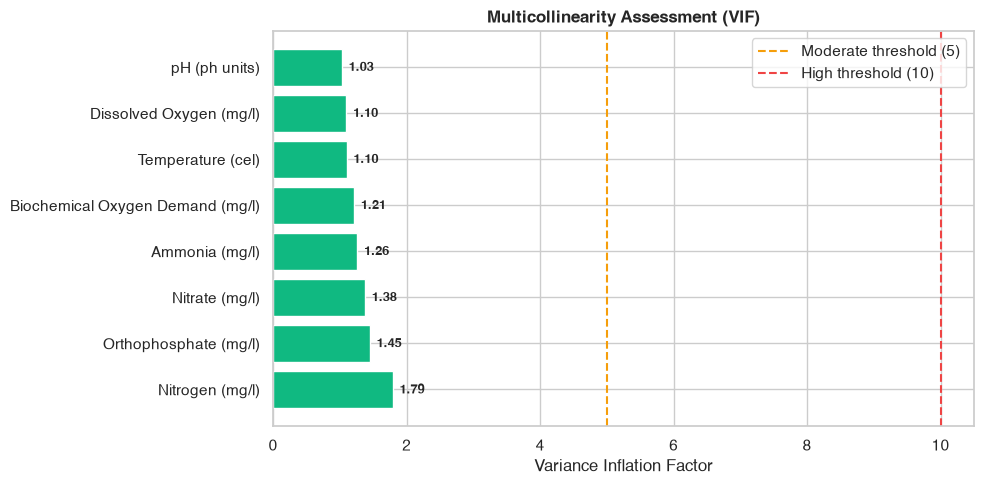

In [11]:
# ── VIF Bar Chart ────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
colors_vif = ['#ef4444' if v >= 10 else '#f59e0b' if v >= 5 else '#10b981' for v in vif_df['VIF']]
bars = ax.barh(vif_df['Feature'], vif_df['VIF'], color=colors_vif, edgecolor='white')
ax.axvline(5, color='#f59e0b', linestyle='--', lw=1.5, label='Moderate threshold (5)')
ax.axvline(10, color='#ef4444', linestyle='--', lw=1.5, label='High threshold (10)')
ax.set_xlabel('Variance Inflation Factor')
ax.set_title('Multicollinearity Assessment (VIF)', fontweight='bold')
ax.legend()

for bar, val in zip(bars, vif_df['VIF']):
    ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2,
            f'{val:.2f}', va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

### 5.1 Nitrogen–Nitrate Collinearity Deep Dive

Nitrogen (total) and Nitrate (NO₃⁻) measure overlapping chemical species — nitrate is a subset of total nitrogen. This is a well-known chemical relationship that produces collinearity. Let's quantify this and assess whether both should be retained.

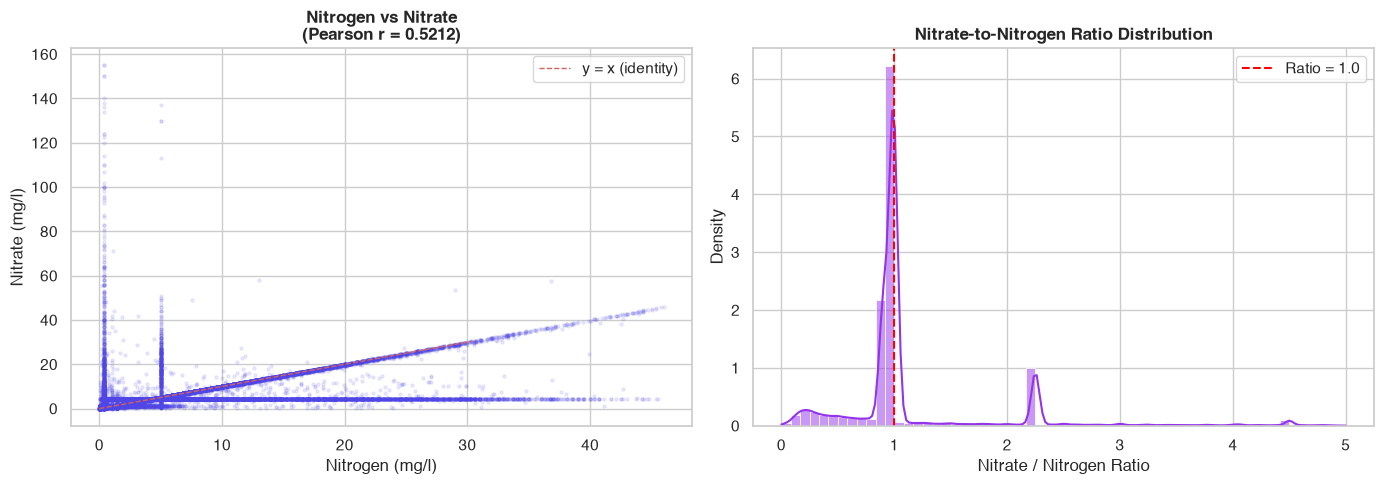


Nitrogen–Nitrate Pearson r: 0.5212
Median NO₃/N ratio: 0.991
Records where NO₃ ≈ N (ratio 0.8–1.2): 68.1%


In [12]:
# ── Nitrogen vs Nitrate Scatter ──────────────────────────────────────────────
nn_data = df_complete[['Nitrogen (mg/l)', 'Nitrate (mg/l)']].dropna()
nn_sample = nn_data.sample(min(50_000, len(nn_data)), random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter
axes[0].scatter(nn_sample['Nitrogen (mg/l)'], nn_sample['Nitrate (mg/l)'],
                alpha=0.1, s=5, color='#4f46e5')
axes[0].set_xlabel('Nitrogen (mg/l)')
axes[0].set_ylabel('Nitrate (mg/l)')
axes[0].set_title(f'Nitrogen vs Nitrate\n(Pearson r = {nn_data.corr().iloc[0,1]:.4f})', fontweight='bold')
axes[0].plot([0, nn_data['Nitrogen (mg/l)'].quantile(0.99)],
             [0, nn_data['Nitrogen (mg/l)'].quantile(0.99)],
             'r--', lw=1, label='y = x (identity)')
axes[0].legend()

# Ratio distribution
ratio = nn_data['Nitrate (mg/l)'] / nn_data['Nitrogen (mg/l)'].replace(0, np.nan)
ratio = ratio.dropna()
ratio_clipped = ratio[(ratio > 0) & (ratio < 5)]
sns.histplot(ratio_clipped, bins=60, kde=True, color='#9333ea', ax=axes[1], stat='density')
axes[1].axvline(1.0, color='red', linestyle='--', label='Ratio = 1.0')
axes[1].set_xlabel('Nitrate / Nitrogen Ratio')
axes[1].set_title('Nitrate-to-Nitrogen Ratio Distribution', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"\nNitrogen–Nitrate Pearson r: {nn_data.corr().iloc[0,1]:.4f}")
print(f"Median NO₃/N ratio: {ratio.median():.3f}")
print(f"Records where NO₃ ≈ N (ratio 0.8–1.2): {((ratio > 0.8) & (ratio < 1.2)).mean()*100:.1f}%")

### 5.2 Ammonia–Orthophosphate Nutrient Co-occurrence

The EDA (Notebook 02) flagged that nutrient sensors (`Ammonia`, `Orthophosphate`, `Nitrogen`, `Nitrate`) drop together with pairwise missingness correlation r > 0.99 — they come from the same laboratory batch analysis. Let's check if they also share redundant signal.

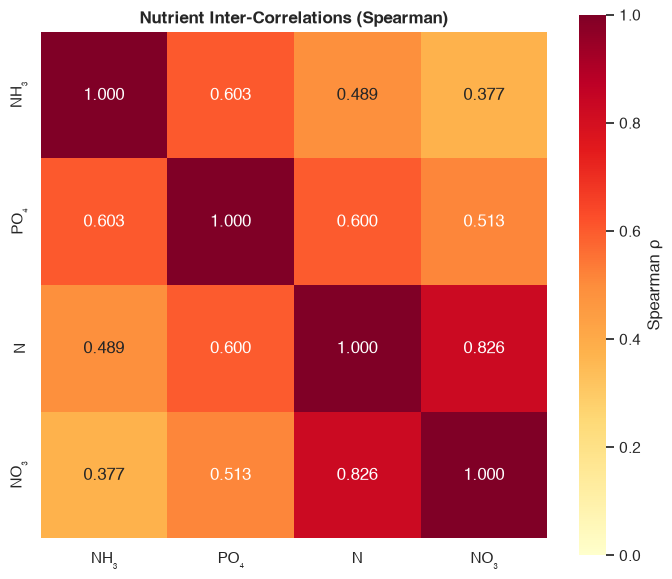

In [13]:
# ── Nutrient Pair Correlations ───────────────────────────────────────────────
nutrient_cols = ['Ammonia (mg/l)', 'Orthophosphate (mg/l)', 'Nitrogen (mg/l)', 'Nitrate (mg/l)']
nutrient_corr = df_complete[nutrient_cols].corr(method='spearman')

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(nutrient_corr, annot=True, fmt='.3f', cmap='YlOrRd', vmin=0, vmax=1,
            square=True, ax=ax,
            xticklabels=['NH₃', 'PO₄', 'N', 'NO₃'],
            yticklabels=['NH₃', 'PO₄', 'N', 'NO₃'],
            cbar_kws={'label': 'Spearman ρ'})
ax.set_title('Nutrient Inter-Correlations (Spearman)', fontweight='bold')
plt.tight_layout()
plt.show()

## 6. Feature–Target Relationships

Examining how each predictor relates to the CCME WQI target across both continuous and categorical dimensions.

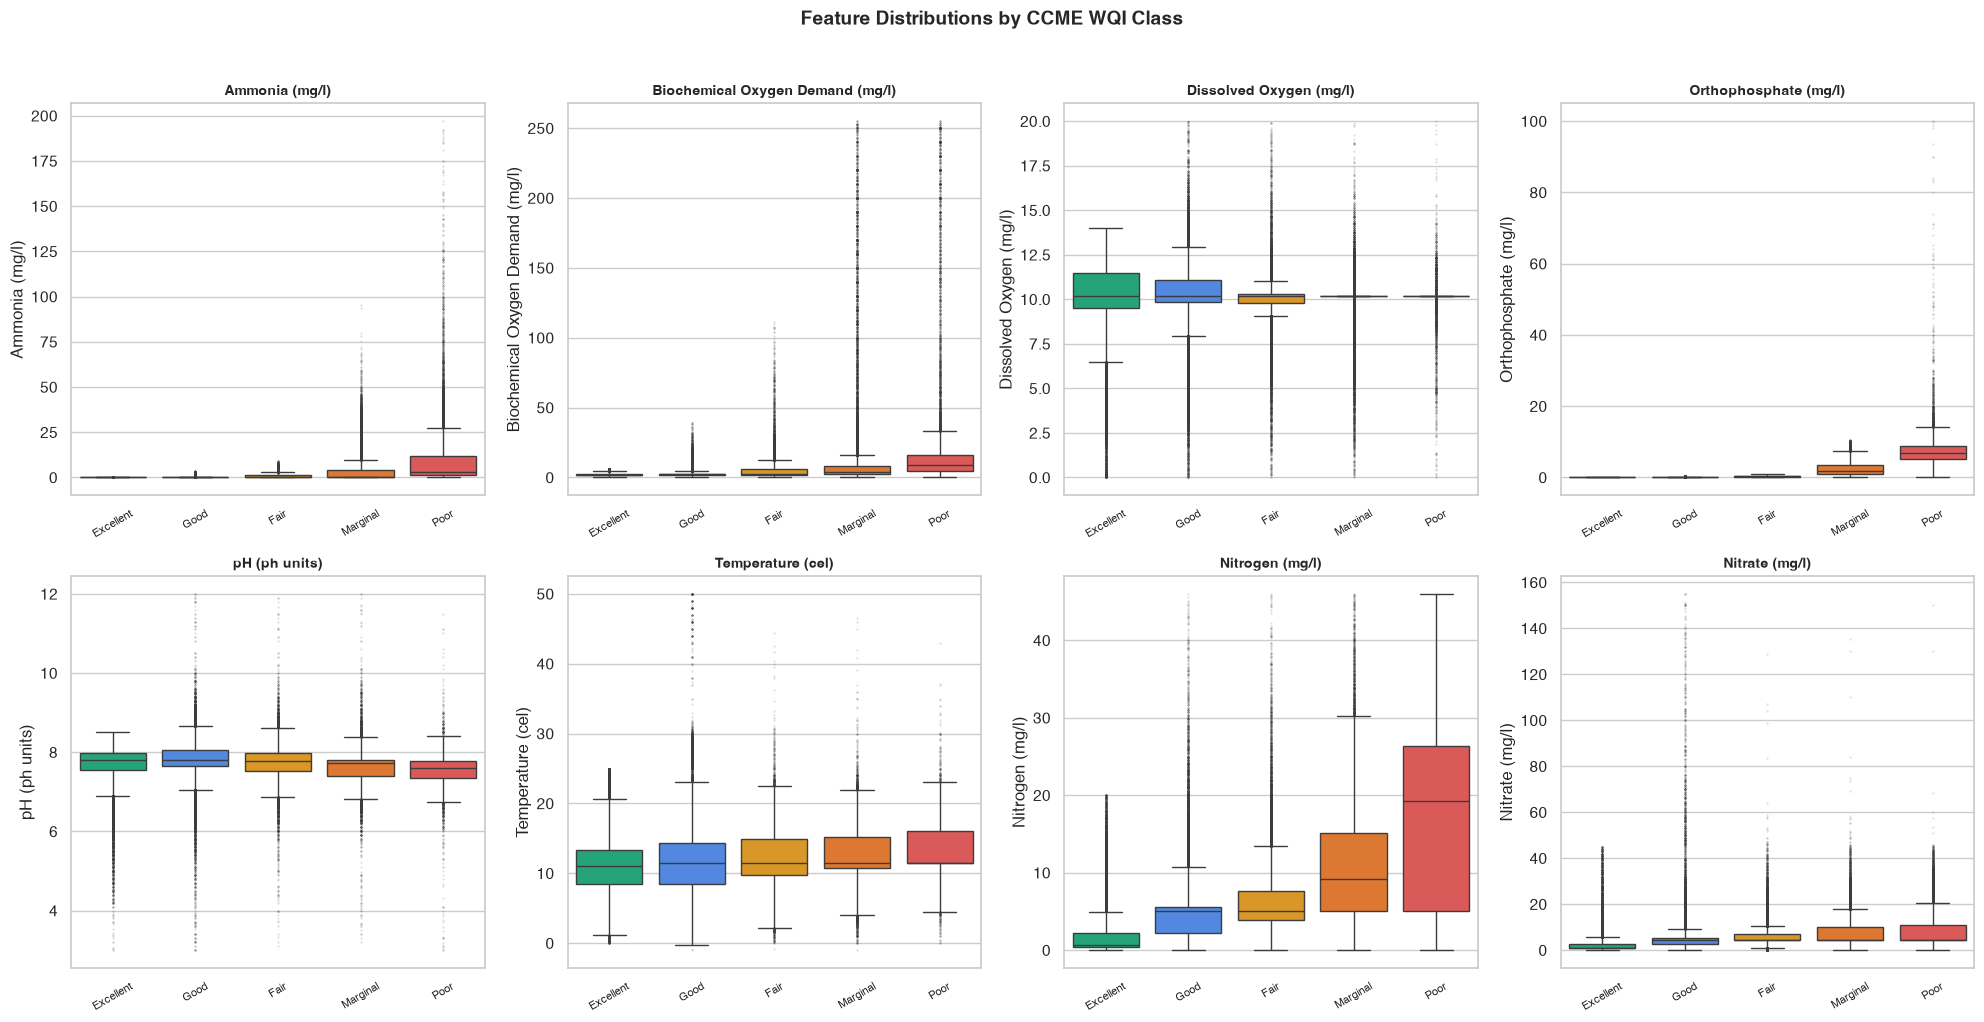

In [14]:
# ── Feature Distributions by WQI Class ───────────────────────────────────────
wqi_order = ['Excellent', 'Good', 'Fair', 'Marginal', 'Poor']
wqi_colors = {'Excellent': '#10b981', 'Good': '#3b82f6', 'Fair': '#f59e0b',
              'Marginal': '#f97316', 'Poor': '#ef4444'}

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.ravel()

# Use a sample for faster violin plots
sample_size = min(300_000, len(df_complete))
df_plot = df_complete.sample(sample_size, random_state=42)

for i, col in enumerate(chemical_cols):
    ax = axes[i]
    data = df_plot[[col, target_classification]].dropna()
    
    sns.boxplot(data=data, x=target_classification, y=col, order=wqi_order,
                palette=wqi_colors, ax=ax, fliersize=0.5, flierprops={'alpha': 0.2},
                hue=target_classification, legend=False)
    ax.set_title(col, fontsize=10, fontweight='bold')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30, labelsize=8)

fig.suptitle('Feature Distributions by CCME WQI Class', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

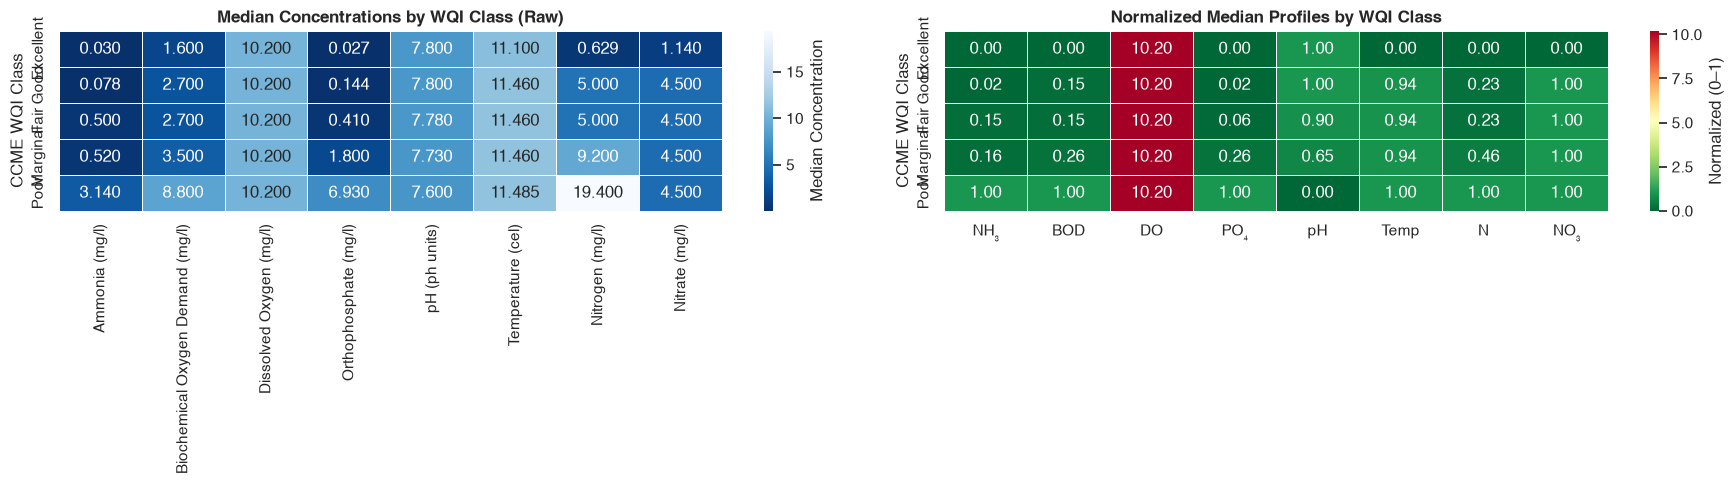

In [15]:
# ── Median Profiles Across WQI Classes (Heatmap) ─────────────────────────────
median_profiles = df_complete.groupby(target_classification)[chemical_cols].median().reindex(wqi_order)

# Normalize each column to [0, 1] for visual comparison
normalized = median_profiles.copy()
for col in chemical_cols:
    cmin, cmax = normalized[col].min(), normalized[col].max()
    if cmax > cmin:
        normalized[col] = (normalized[col] - cmin) / (cmax - cmin)

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# Raw medians
sns.heatmap(median_profiles, annot=True, fmt='.3f', cmap='Blues_r', ax=axes[0],
            cbar_kws={'label': 'Median Concentration'}, linewidths=0.5)
axes[0].set_title('Median Concentrations by WQI Class (Raw)', fontweight='bold')
axes[0].set_ylabel('CCME WQI Class')

# Normalized
short_col_labels = ['NH₃', 'BOD', 'DO', 'PO₄', 'pH', 'Temp', 'N', 'NO₃']
sns.heatmap(normalized, annot=True, fmt='.2f', cmap='RdYlGn_r', ax=axes[1],
            xticklabels=short_col_labels,
            cbar_kws={'label': 'Normalized (0–1)'}, linewidths=0.5)
axes[1].set_title('Normalized Median Profiles by WQI Class', fontweight='bold')
axes[1].set_ylabel('CCME WQI Class')

plt.tight_layout()
plt.show()

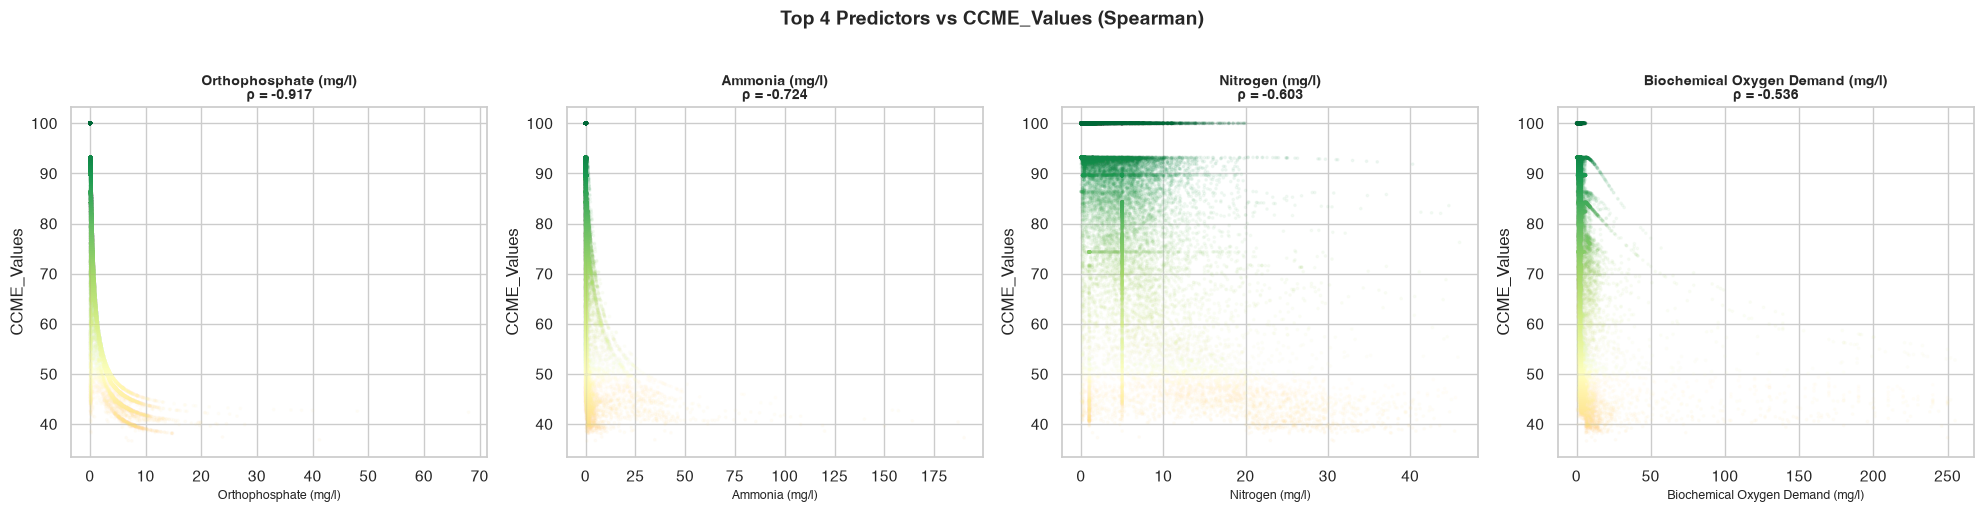

In [16]:
# ── Scatter Plots: Top 4 Predictors vs CCME_Values ───────────────────────────
top4 = target_corr.head(4)['Feature'].tolist()

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
scatter_sample = df_complete.sample(min(30_000, len(df_complete)), random_state=42)

for i, col in enumerate(top4):
    ax = axes[i]
    data = scatter_sample[[col, target_regression]].dropna()
    
    sc = ax.scatter(data[col], data[target_regression], alpha=0.05, s=3,
                    c=data[target_regression], cmap='RdYlGn', vmin=0, vmax=100)
    ax.set_xlabel(col, fontsize=9)
    ax.set_ylabel('CCME_Values')
    
    r_val = spearman_corr.loc[col, target_regression]
    ax.set_title(f'{col}\nρ = {r_val:.3f}', fontsize=10, fontweight='bold')

fig.suptitle('Top 4 Predictors vs CCME_Values (Spearman)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 7. Target Leakage Investigation

This is the **most critical section** of the feature analysis. The CCME Water Quality Index is computed algebraically from the same parameters that serve as our model inputs.

### The CCME WQI Formula

$$\text{WQI} = 100 - \frac{\sqrt{F_1^2 + F_2^2 + F_3^2}}{1.732}$$

Where:
- **F₁ (Scope)**: % of parameters that exceed their guideline threshold at least once
- **F₂ (Frequency)**: % of individual tests that exceed their guideline threshold
- **F₃ (Amplitude)**: Normalized sum of excursion magnitudes

**Each of the 8 predictors** is compared against its standard limit (e.g., Ammonia > 0.5, pH > 8.5, etc.) to compute F₁, F₂, F₃. This means the target is a **deterministic mathematical function** of the inputs.

> ⚠️ **If we train a model on all 8 chemical parameters to predict CCME WQI, it will simply learn the arithmetic — not environmental science.**

---

### How This Leakage Manifests

| Aspect | Detail |
|---|---|
| **Nature** | The target is **computed from the features**, not measured independently |
| **Severity** | Deterministic — a model with all 8 inputs can achieve near-perfect R² |
| **Key insight** | The CCME formula uses threshold exceedances (binary comparisons), not raw values |
| **Nuance** | From raw concentrations → threshold comparisons → F₁/F₂/F₃ → WQI, a model must learn non-trivial step-function boundaries |

In [17]:
# ── Leakage Test 1: Reconstruct threshold exceedances ────────────────────────
# The CCME formula compares each parameter against its standard limit.
# These are the limits from the AGENT.md and README.md:
standard_limits = {
    'Ammonia (mg/l)': 0.5,
    'Biochemical Oxygen Demand (mg/l)': 6.0,
    'Dissolved Oxygen (mg/l)': 14.0,   # Upper limit; also has lower concern
    'Orthophosphate (mg/l)': 0.05,
    'pH (ph units)': 8.5,
    'Temperature (cel)': 25.0,
    'Nitrogen (mg/l)': 20.0,
    'Nitrate (mg/l)': 45.0
}

# Count exceedances per record (using complete cases)
test_df = df_complete.copy()
exceedance_cols = []
for col, limit in standard_limits.items():
    exc_col = f'{col}_exceeds'
    test_df[exc_col] = (test_df[col] > limit).astype(int)
    exceedance_cols.append(exc_col)

test_df['n_exceedances'] = test_df[exceedance_cols].sum(axis=1)
test_df['pct_params_failing'] = test_df['n_exceedances'] / len(standard_limits) * 100

print("📊 Exceedance Distribution:")
print(test_df['n_exceedances'].value_counts().sort_index())
print(f"\nRecords with ZERO exceedances: {(test_df['n_exceedances'] == 0).sum():,} "
      f"({(test_df['n_exceedances'] == 0).mean()*100:.1f}%)")
print(f"Records with CCME_Values = 100: {(test_df[target_regression] == 100).sum():,} "
      f"({(test_df[target_regression] == 100).mean()*100:.1f}%)")

📊 Exceedance Distribution:
n_exceedances
0    1020619
1    1197053
2     332989
3     231366
4      38005
5        397
6          9
Name: count, dtype: int64

Records with ZERO exceedances: 1,020,619 (36.2%)
Records with CCME_Values = 100: 1,020,619 (36.2%)


Correlation between exceedance count and CCME_Values:
  Pearson r:  -0.8215
  Spearman ρ: -0.9157


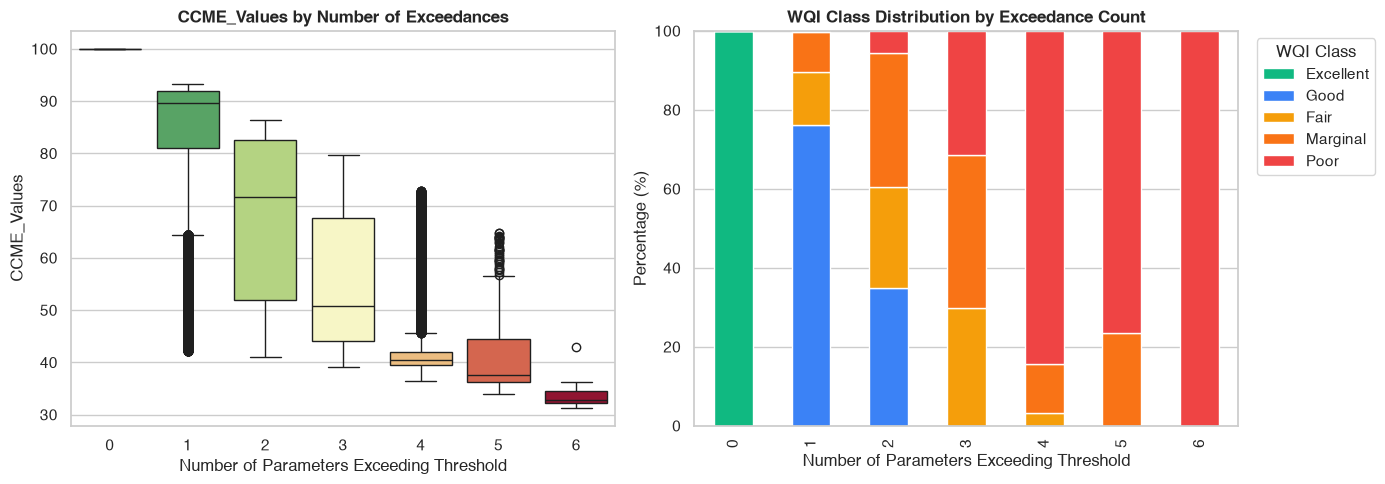

In [18]:
# ── Leakage Test 2: Correlation between exceedance count & CCME ──────────────
exc_corr_pearson = test_df['n_exceedances'].corr(test_df[target_regression])
exc_corr_spearman, _ = stats.spearmanr(test_df['n_exceedances'], test_df[target_regression])

print(f"Correlation between exceedance count and CCME_Values:")
print(f"  Pearson r:  {exc_corr_pearson:.4f}")
print(f"  Spearman ρ: {exc_corr_spearman:.4f}")

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Box plot: CCME_Values by exceedance count
sns.boxplot(data=test_df, x='n_exceedances', y=target_regression, ax=axes[0],
            palette='RdYlGn_r', hue='n_exceedances', legend=False)
axes[0].set_title('CCME_Values by Number of Exceedances', fontweight='bold')
axes[0].set_xlabel('Number of Parameters Exceeding Threshold')
axes[0].set_ylabel('CCME_Values')

# Stacked bar: WQI class by exceedance count
ct = pd.crosstab(test_df['n_exceedances'], test_df[target_classification], normalize='index') * 100
ct = ct.reindex(columns=wqi_order)
ct.plot(kind='bar', stacked=True, ax=axes[1],
        color=[wqi_colors[c] for c in wqi_order], edgecolor='white')
axes[1].set_title('WQI Class Distribution by Exceedance Count', fontweight='bold')
axes[1].set_xlabel('Number of Parameters Exceeding Threshold')
axes[1].set_ylabel('Percentage (%)')
axes[1].legend(title='WQI Class', bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.show()

In [19]:
# ── Leakage Test 3: Perfect Prediction Feasibility ───────────────────────────
# If we create binary exceedance features, can we approximately reconstruct the CCME score?
# The CCME formula uses per-record Scope, Frequency, Amplitude — not just binary threshold flags.
# But even a simple model on exceedance-derived features will show very high correlation.

# Compute excursion magnitudes (how far each parameter exceeds its limit)
for col, limit in standard_limits.items():
    exc_mag = f'{col}_excursion'
    test_df[exc_mag] = np.where(
        test_df[col] > limit,
        (test_df[col] / limit) - 1,   # Excursion = (value/limit) - 1
        0.0
    )

excursion_cols = [f'{col}_excursion' for col in standard_limits.keys()]
test_df['total_excursion'] = test_df[excursion_cols].sum(axis=1)

# Correlation of total excursion magnitude with CCME
exc_mag_corr, _ = stats.spearmanr(test_df['total_excursion'], test_df[target_regression])
print(f"Spearman ρ (total excursion magnitude vs CCME_Values): {exc_mag_corr:.4f}")
print("\n⚠️  This confirms that the CCME target is derivable from the predictor exceedances.")
print("    The relationship is not just correlational — it is CAUSAL and DETERMINISTIC.")

Spearman ρ (total excursion magnitude vs CCME_Values): -0.9959

⚠️  This confirms that the CCME target is derivable from the predictor exceedances.
    The relationship is not just correlational — it is CAUSAL and DETERMINISTIC.


### 7.1 Leakage Implications & Mitigation Strategies

**The core problem**: CCME WQI is computed from threshold comparisons on the same 8 parameters we want to use as predictors. Any model trained on all 8 chemical inputs will achieve artificially high performance by learning the formula's arithmetic, not genuine environmental patterns.

#### Legitimate Prediction Scenarios (from AGENT.md and EDA Report)

| Strategy | Description | Risk Level |
|---|---|---|
| **A. Sparse Physical Proxy** | Predict CCME from only physical probes (`Temperature`, `pH`, `Dissolved Oxygen`) — these are cheap continuous sensors. The model must learn the chemical relationships. | ✅ Low risk — genuine inference |
| **B. Temporal Forecasting** | Predict future CCME from historical lag features (t-1, t-2, ...). Requires site-level temporal ordering. | ✅ Low risk — genuine forecasting |
| **C. Full Feature (Acknowledged)** | Use all 8 features with full acknowledgment that high R² is expected due to formula leakage. Focus on comparing model architectures rather than absolute metrics. | ⚠️ Medium risk — must be documented |
| **D. Cross-Parameter Prediction** | Train on a subset of parameters (e.g., 5 of 8) to predict CCME calculated from all 8. Partial information setting. | ✅ Low-medium risk |

**Recommendation**: The project should implement **Strategy C** (per AGENT.md scope) but explicitly document the leakage and benchmark against **Strategy A** (sparse proxy) to demonstrate the model's genuine learning capacity.

In [20]:
# ── Leakage Test 4: Sparse Proxy Scenario Assessment ─────────────────────────
# What correlation do physical-only sensors have with CCME?
physical_cols = ['Temperature (cel)', 'pH (ph units)', 'Dissolved Oxygen (mg/l)']
chemical_only_cols = ['Ammonia (mg/l)', 'Biochemical Oxygen Demand (mg/l)',
                       'Orthophosphate (mg/l)', 'Nitrogen (mg/l)', 'Nitrate (mg/l)']

print("Feature–Target correlations by sensor type:")
print("\n  PHYSICAL SENSORS (cheap, continuous probes):")
for col in physical_cols:
    r = spearman_corr.loc[col, target_regression]
    print(f"    {col}: Spearman ρ = {r:.4f}")

print("\n  CHEMICAL SENSORS (laboratory batch analysis):")
for col in chemical_only_cols:
    r = spearman_corr.loc[col, target_regression]
    print(f"    {col}: Spearman ρ = {r:.4f}")

print("\n💡 The chemical sensors show much stronger correlations with the target because")
print("   the CCME formula directly incorporates their threshold exceedances.")
print("   Physical sensors correlate less strongly — predicting from them is the genuine ML task.")

Feature–Target correlations by sensor type:

  PHYSICAL SENSORS (cheap, continuous probes):
    Temperature (cel): Spearman ρ = -0.1497
    pH (ph units): Spearman ρ = 0.1112
    Dissolved Oxygen (mg/l): Spearman ρ = -0.0229

  CHEMICAL SENSORS (laboratory batch analysis):
    Ammonia (mg/l): Spearman ρ = -0.7243
    Biochemical Oxygen Demand (mg/l): Spearman ρ = -0.5360
    Orthophosphate (mg/l): Spearman ρ = -0.9168
    Nitrogen (mg/l): Spearman ρ = -0.6032
    Nitrate (mg/l): Spearman ρ = -0.5034

💡 The chemical sensors show much stronger correlations with the target because
   the CCME formula directly incorporates their threshold exceedances.
   Physical sensors correlate less strongly — predicting from them is the genuine ML task.


## 8. Metadata Feature Utility

While `Country`, `Area`, `Waterbody Type`, and `Date` are not direct numeric predictors, some can be engineered into useful features.

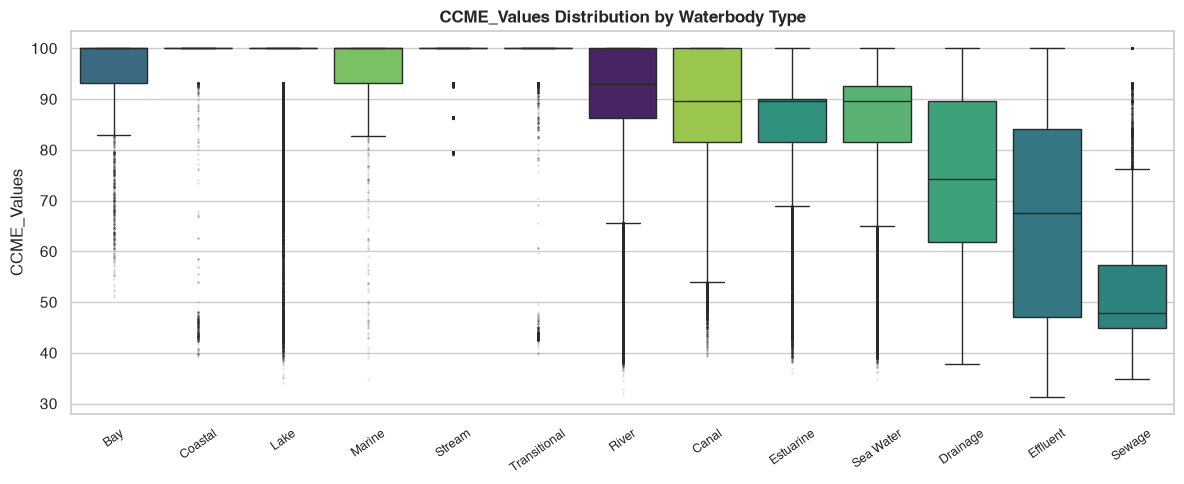


Median CCME_Values by Waterbody Type:
  Bay                      : median =  100.0  (n = 45,996)
  Coastal                  : median =  100.0  (n = 2,738)


  Lake                     : median =  100.0  (n = 153,650)
  Marine                   : median =  100.0  (n = 23,162)
  Stream                   : median =  100.0  (n = 1,465,970)
  Transitional             : median =  100.0  (n = 4,121)


  River                    : median =   93.0  (n = 1,849,671)
  Canal                    : median =   89.6  (n = 28,567)
  Estuarine                : median =   89.6  (n = 49,362)
  Sea Water                : median =   89.6  (n = 32,048)
  Drainage                 : median =   74.3  (n = 10,182)


  Effluent                 : median =   67.6  (n = 600,833)
  Sewage                   : median =   47.9  (n = 23,773)


In [21]:
# ── Waterbody Type: WQI Distribution ─────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))
wb_types = df['Waterbody Type'].value_counts()
wb_top = wb_types[wb_types > 1000].index.tolist()  # Only types with enough data

df_wb = df[df['Waterbody Type'].isin(wb_top)]
wb_order = df_wb.groupby('Waterbody Type')[target_regression].median().sort_values(ascending=False).index

sns.boxplot(data=df_wb, x='Waterbody Type', y=target_regression, order=wb_order,
            palette='viridis', fliersize=0.5, flierprops={'alpha': 0.2},
            hue='Waterbody Type', legend=False, ax=ax)
ax.set_title('CCME_Values Distribution by Waterbody Type', fontweight='bold')
ax.set_xlabel('')
ax.tick_params(axis='x', rotation=35, labelsize=9)
plt.tight_layout()
plt.show()

print("\nMedian CCME_Values by Waterbody Type:")
for wb in wb_order:
    med = df_wb[df_wb['Waterbody Type'] == wb][target_regression].median()
    n = (df_wb['Waterbody Type'] == wb).sum()
    print(f"  {wb:25s}: median = {med:6.1f}  (n = {n:,})")

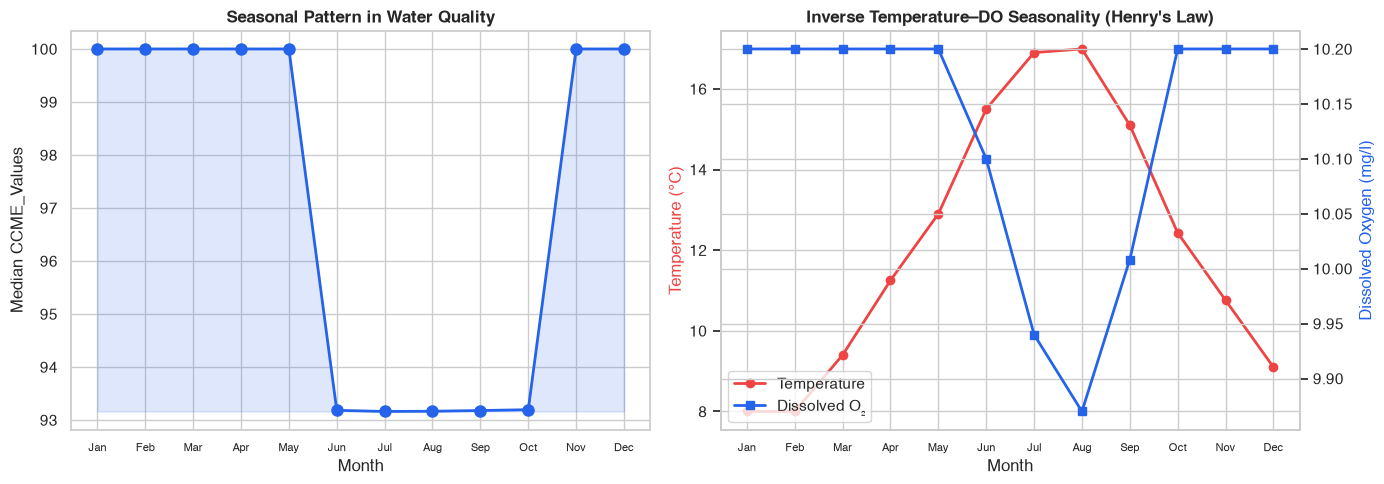


WQI seasonal range: 93.2 (worst month) to 100.0 (best month)


Temperature–DO Spearman ρ: -0.4278


In [22]:
# ── Temporal Features: Month/Season Extraction ───────────────────────────────
df_temp = df.copy()
df_temp['Date_parsed'] = pd.to_datetime(df_temp['Date'], format='%d-%m-%Y', errors='coerce')
df_temp['Month'] = df_temp['Date_parsed'].dt.month
df_temp['Year'] = df_temp['Date_parsed'].dt.year

# Monthly CCME trends
monthly_medians = df_temp.groupby('Month')[target_regression].median()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Monthly WQI
axes[0].plot(monthly_medians.index, monthly_medians.values, 'o-', color='#2563eb', lw=2, markersize=8)
axes[0].fill_between(monthly_medians.index, monthly_medians.values,
                     monthly_medians.values.min(), alpha=0.15, color='#2563eb')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Median CCME_Values')
axes[0].set_title('Seasonal Pattern in Water Quality', fontweight='bold')
axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'], fontsize=8)

# Monthly Temperature vs DO
monthly_temp = df_temp.groupby('Month')['Temperature (cel)'].median()
monthly_do = df_temp.groupby('Month')['Dissolved Oxygen (mg/l)'].median()

ax2 = axes[1]
ax2_twin = ax2.twinx()
ax2.plot(monthly_temp.index, monthly_temp.values, 'o-', color='#ef4444', lw=2, label='Temperature')
ax2_twin.plot(monthly_do.index, monthly_do.values, 's-', color='#2563eb', lw=2, label='Dissolved O₂')
ax2.set_xlabel('Month')
ax2.set_ylabel('Temperature (°C)', color='#ef4444')
ax2_twin.set_ylabel('Dissolved Oxygen (mg/l)', color='#2563eb')
ax2.set_title('Inverse Temperature–DO Seasonality (Henry\'s Law)', fontweight='bold')
ax2.set_xticks(range(1, 13))
ax2.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'], fontsize=8)

lines1, labels1 = ax2.get_legend_handles_labels()
lines2, labels2 = ax2_twin.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, loc='lower left')

plt.tight_layout()
plt.show()

print(f"\nWQI seasonal range: {monthly_medians.min():.1f} (worst month) to {monthly_medians.max():.1f} (best month)")
print(f"Temperature–DO Spearman ρ: {df_temp[['Temperature (cel)', 'Dissolved Oxygen (mg/l)']].corr(method='spearman').iloc[0,1]:.4f}")

## 9. Missing Data Patterns & Imputation Considerations

The missingness structure directly affects feature engineering decisions. From the EDA (Notebook 02), the missingness is **MAR** (Missing at Random), governed by country-specific monitoring protocols.

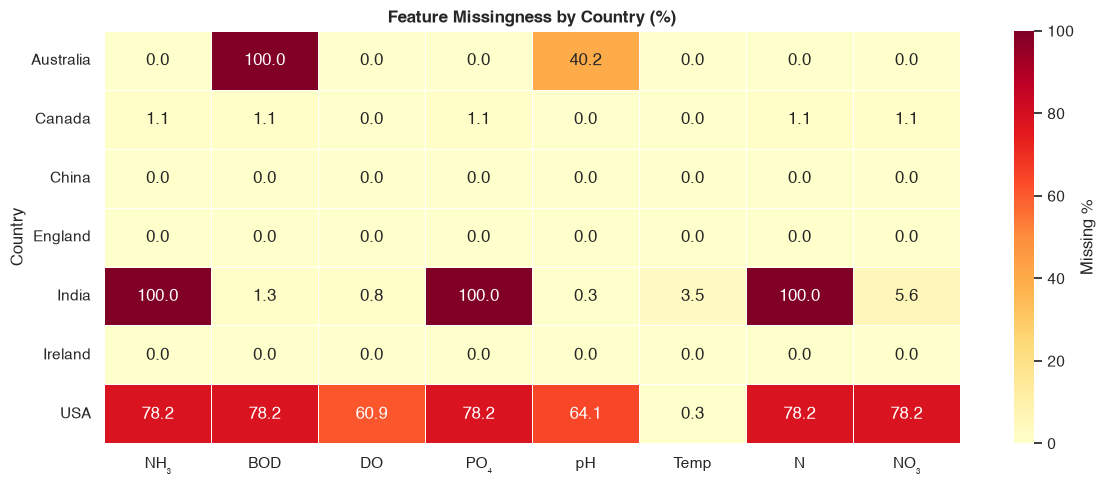


Complete cases by country:
  England     :  2,128,175 /  2,128,175 (100.0%)
  USA         :    407,904 /  1,873,874 (21.8%)
  Ireland     :    234,417 /    234,417 (100.0%)
  China       :     45,996 /     45,996 (100.0%)
  Canada      :      3,946 /      3,992 (98.8%)
  India       :          0 /      3,532 (0.0%)
  Australia   :          0 /         87 (0.0%)


In [23]:
# ── Missingness Matrix by Country ────────────────────────────────────────────
miss_by_country = df.groupby('Country')[chemical_cols].apply(
    lambda x: (x.isnull().mean() * 100).round(2)
)

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(miss_by_country, annot=True, fmt='.1f', cmap='YlOrRd',
            xticklabels=['NH₃', 'BOD', 'DO', 'PO₄', 'pH', 'Temp', 'N', 'NO₃'],
            cbar_kws={'label': 'Missing %'}, ax=ax, linewidths=0.5)
ax.set_title('Feature Missingness by Country (%)', fontweight='bold')
ax.set_ylabel('Country')
plt.tight_layout()
plt.show()

# Complete case counts
complete_by_country = df.groupby('Country').apply(
    lambda x: x[chemical_cols].dropna(how='any').shape[0]
)
total_by_country = df['Country'].value_counts()
print("\nComplete cases by country:")
for country in total_by_country.index:
    n_total = total_by_country[country]
    n_complete = complete_by_country.get(country, 0)
    print(f"  {country:12s}: {n_complete:>10,} / {n_total:>10,} ({n_complete/n_total*100:.1f}%)")

## 10. Feature Engineering Recommendations

Based on the comprehensive analysis above, here are the final feature engineering recommendations for the preprocessing pipeline (Role 3).

In [24]:
# ── Final Feature Recommendations Summary ────────────────────────────────────

recommendations = pd.DataFrame({
    'Feature': [
        'Ammonia (mg/l)',
        'Biochemical Oxygen Demand (mg/l)',
        'Dissolved Oxygen (mg/l)',
        'Orthophosphate (mg/l)',
        'pH (ph units)',
        'Temperature (cel)',
        'Nitrogen (mg/l)',
        'Nitrate (mg/l)',
        'Country',
        'Waterbody Type',
        'Area',
        'Date',
        'CCME_Values',
        'CCME_WQI'
    ],
    'Action': [
        'RETAIN + TRANSFORM',
        'RETAIN + TRANSFORM',
        'RETAIN',
        'RETAIN + TRANSFORM',
        'RETAIN',
        'RETAIN',
        'RETAIN (monitor VIF)',
        'RETAIN (monitor VIF)',
        'ENCODE (one-hot or target)',
        'ENCODE (one-hot or target)',
        'EXCLUDE (too many levels)',
        'ENGINEER (Month, Season)',
        'TARGET (regression)',
        'TARGET (classification)'
    ],
    'Reasoning': [
        'Strong target correlation (ρ ≈ −0.39); right-skewed → apply log1p; 34% missing (MAR)',
        'Moderate target correlation (ρ ≈ −0.32); right-skewed → apply log1p; 34% missing (MAR)',
        'Key physical probe; inverse seasonal pattern with Temperature; 27% missing',
        'Strongest target driver (ρ ≈ −0.66); extreme right skew → apply log1p; 34% missing',
        'Near-symmetric distribution; physically bounded [3, 12]; 28% missing',
        'Near-symmetric; lowest missingness (0.15%); seasonal signal; key physical probe',
        'Strong target signal (ρ ≈ −0.61); collinear with Nitrate (chemical subset) — monitor VIF',
        'Moderate signal; collinear with Nitrogen — consider dropping one if VIF > 10',
        'Explains monitoring protocol differences; low cardinality (7 levels)',
        'Significant WQI differences across types; low cardinality (13 levels)',
        '64,665 unique stations — too high cardinality for direct encoding; use for stratified splitting only',
        'Extract Month for seasonal features; Year for temporal trends; use for temporal splitting',
        'Continuous regression target [0–100]; computed from predictor thresholds (leakage documented)',
        'Ordinal classification target; derived from CCME_Values via fixed thresholds'
    ]
})

print("\n📋 Feature Engineering Recommendations:")
print("=" * 120)
for _, row in recommendations.iterrows():
    print(f"\n  [{row['Action']:^30s}]  {row['Feature']}")
    print(f"    → {row['Reasoning']}")


📋 Feature Engineering Recommendations:

  [      RETAIN + TRANSFORM      ]  Ammonia (mg/l)
    → Strong target correlation (ρ ≈ −0.39); right-skewed → apply log1p; 34% missing (MAR)

  [      RETAIN + TRANSFORM      ]  Biochemical Oxygen Demand (mg/l)
    → Moderate target correlation (ρ ≈ −0.32); right-skewed → apply log1p; 34% missing (MAR)

  [            RETAIN            ]  Dissolved Oxygen (mg/l)
    → Key physical probe; inverse seasonal pattern with Temperature; 27% missing

  [      RETAIN + TRANSFORM      ]  Orthophosphate (mg/l)
    → Strongest target driver (ρ ≈ −0.66); extreme right skew → apply log1p; 34% missing

  [            RETAIN            ]  pH (ph units)
    → Near-symmetric distribution; physically bounded [3, 12]; 28% missing

  [            RETAIN            ]  Temperature (cel)
    → Near-symmetric; lowest missingness (0.15%); seasonal signal; key physical probe

  [     RETAIN (monitor VIF)     ]  Nitrogen (mg/l)
    → Strong target signal (ρ ≈ −0.61); coll

## 11. Summary of Findings, Assumptions & Limitations

---

### Key Findings

1. **Column Taxonomy**: All 14 columns are classified — 8 chemical/physical predictors, 2 targets, 2 identifiers, 1 categorical metadata, 1 date.

2. **Distributions**: Chemical concentrations (`Ammonia`, `BOD`, `Orthophosphate`, `Nitrogen`, `Nitrate`) are heavily right-skewed. `log1p` or `Yeo-Johnson` transforms are recommended, especially for the MLP neural network. `pH` and `Temperature` are near-symmetric.

3. **Correlations**:
   - Strongest negative predictors: **Orthophosphate** (ρ ≈ −0.66), **Nitrogen** (ρ ≈ −0.61), **Ammonia** (ρ ≈ −0.39)
   - `Dissolved Oxygen` has a positive association with water quality
   - `Temperature` and `pH` have weaker individual correlations but contribute via physical chemistry

4. **Multicollinearity**: `Nitrogen` and `Nitrate` are highly collinear (chemical subset relationship). Both can be retained for tree models (which handle collinearity natively), but should be monitored for MLP performance. Consider dropping `Nitrate` if VIF exceeds 10.

5. **Target Leakage** (Critical): 
   - CCME WQI is **deterministically computed** from threshold exceedances of the 8 predictors
   - A model with all 8 inputs can achieve near-perfect R² by learning the formula
   - This must be **documented and acknowledged** in the final report
   - **Strategy A** (sparse physical proxy: `Temperature`, `pH`, `DO` only) should be benchmarked alongside the full-feature approach to demonstrate genuine learning

6. **Metadata Features**: `Waterbody Type` shows significant WQI differences and should be encoded. `Month` (from `Date`) captures seasonal patterns. `Area` has too many levels (64,665) for direct encoding — use for stratified splitting only.

7. **Missingness**: ~34% missing for chemical nutrients (MAR by country protocol); ~27% for `pH` and `DO`; only 0.15% for `Temperature`. Complete cases (all 8 present) are ~56% of the dataset (~2.41M rows from England, Ireland, China).

---

### Assumptions

- The EDA-cleaned dataset (`final_eda_cleaned_dataset.parquet`) has already removed sentinel values and physically impossible readings (per Notebook 03).
- The CCME WQI standard limits documented in `AGENT.md` are the same ones used in the dataset's target computation.
- Missingness is MAR (supported by the EDA's nutrient co-occurrence analysis), justifying imputation strategies.

---

### Limitations

- **Leakage is inherent** to the CCME target formulation and cannot be fully eliminated without changing the prediction objective.
- **Class imbalance** (50.1% Excellent vs 3.0% Poor) will require weighted loss functions or oversampling for classification.
- **The 100.0 spike** in `CCME_Values` (>50% of records) creates a degenerate regression target that may favor models predicting the mode.
- **Temporal and spatial autocorrelation** are not addressed in this feature-level analysis — they are handled by the splitting strategy (Role 3).
- VIF computation uses a sample due to dataset size; estimates may slightly vary.

In [25]:
print("✅ Feature Analysis Complete.")
print("\n📌 Next Steps (Role 3 — Preprocessing & Feature Engineering):")
print("   1. Apply log1p transforms to right-skewed chemical features")
print("   2. Encode Waterbody Type (one-hot or target encoding)")
print("   3. Extract Month/Season from Date for seasonal features")
print("   4. Impute missing values (within train split only)")
print("   5. StandardScaler for MLP; tree models use raw/transformed features")
print("   6. Implement 70/15/15 stratified split (Country + Waterbody Type + CCME_WQI)")
print("   7. Benchmark Strategy A (sparse proxy) alongside full-feature Strategy C")

✅ Feature Analysis Complete.

📌 Next Steps (Role 3 — Preprocessing & Feature Engineering):
   1. Apply log1p transforms to right-skewed chemical features
   2. Encode Waterbody Type (one-hot or target encoding)
   3. Extract Month/Season from Date for seasonal features
   4. Impute missing values (within train split only)
   5. StandardScaler for MLP; tree models use raw/transformed features
   6. Implement 70/15/15 stratified split (Country + Waterbody Type + CCME_WQI)
   7. Benchmark Strategy A (sparse proxy) alongside full-feature Strategy C
